# Heart Disease — Exploratory Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
df = pd.read_csv("Data/heart-disease.csv")
df.shape

(303, 14)

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,76.0,female,Non-anginal pain,140,197,False,Left ventricular hypertrophy,116,no,1.1,Flatsloping,0,2,1
1,55.0,female,Typical angina,180,327,False,Left ventricular hypertrophy,117,yes,3.4,Flatsloping,0,2,0
2,55.0,female,Typical angina,128,205,False,Left ventricular hypertrophy,130,yes,2.0,Flatsloping,1,3,0
3,58.0,male,Typical angina,114,318,False,Left ventricular hypertrophy,140,no,4.4,Upsloping,3,1,0
4,63.0,male,Asymptomatic,145,233,True,Nothing to note,150,no,2.3,Upsloping,0,1,1


In [4]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')

**Insight:** 303 rows and 14 columns. 

## 2. Dataset overview

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       299 non-null    float64
 1   sex       299 non-null    str    
 2   cp        303 non-null    str    
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    bool   
 6   restecg   303 non-null    str    
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    str    
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    str    
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: bool(1), float64(2), int64(6), str(5)
memory usage: 31.2 KB


In [6]:
df.isna().sum()

age         4
sex         4
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [7]:
df.describe()

,age,trestbps,chol,thalach,oldpeak,ca,thal,target
count,299.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.314381,131.623762,246.264026,149.646865,1.039604,0.729373,2.313531,0.544554
std,9.033578,17.538143,51.830751,22.905161,1.161075,1.022606,0.612277,0.498835
min,29.000000,94.000000,126.000000,71.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,120.000000,211.000000,133.500000,0.000000,0.000000,2.000000,0.000000
50%,55.000000,130.000000,240.000000,153.000000,0.800000,0.000000,2.000000,1.000000
75%,61.000000,140.000000,274.500000,166.000000,1.600000,1.000000,3.000000,1.000000
max,77.000000,200.000000,564.000000,202.000000,6.200000,4.000000,3.000000,1.000000


**Insight:** Missingness is small but real  about 4 values each in `age` and `sex`. Numeric ranges look plausible (e.g. resting BP and cholesterol). Decide early whether to drop or impute those few rows so they do not silently shrink stratified splits.

## 3. Feature imbalance

In [8]:
df["sex"].value_counts(dropna=False)

sex
male      206
female     93
NaN         4
Name: count, dtype: int64

In [10]:
df["sex"].value_counts(normalize=True)*100

sex
male      68.896321
female    31.103679
Name: proportion, dtype: float64

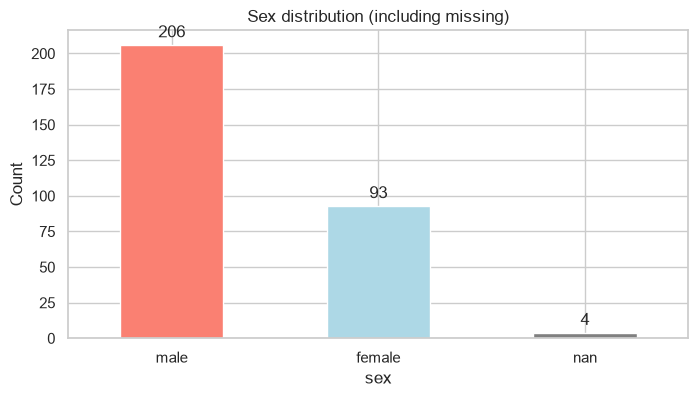

In [10]:
ax = df["sex"].value_counts(dropna=False).plot(
    kind="bar",
    color=["salmon", "lightblue", "gray"],
    figsize=(8, 4),
)

plt.title("Sex distribution (including missing)")
plt.xlabel("sex")
plt.ylabel("Count")
plt.xticks(rotation=0)

ax.bar_label(ax.containers[0], padding=3)

plt.show()

**Insight:** The sample is male-heavy (~206 male vs ~93 female, plus a few missing). Prefer stratified train/test splits (and watch metrics by sex) so the minority group is not under-represented in evaluation.

## 4. Target distribution

`target`: 1 = heart disease, 0 = no disease

In [11]:
df["target"].value_counts()

target
1    165
0    138
Name: count, dtype: int64

In [12]:
df["target"].value_counts(normalize=True) * 100

target
1    54.455446
0    45.544554
Name: proportion, dtype: float64

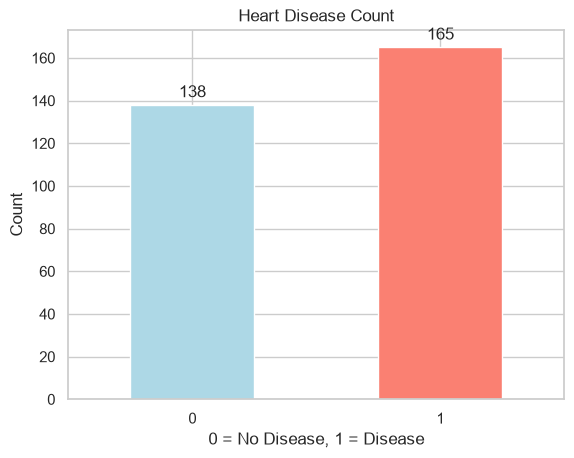

In [13]:
ax = df["target"].value_counts().sort_index().plot(
    kind="bar",
    color=["lightblue", "salmon"],
)
plt.title("Heart Disease Count")
plt.xlabel("0 = No Disease, 1 = Disease")
plt.ylabel("Count")
plt.xticks(rotation=0)
ax.bar_label(ax.containers[0], padding=3)
plt.show()

**Insight:** Classes are nearly balanced (~165 disease / ~138 no disease, about 54% / 46%). Accuracy is a reasonable headline metric here, but still report recall/ROC-AUC so false negatives are visible.

## 5. Heart disease frequency by sex

In [14]:
pd.crosstab(df["target"], df["sex"])

sex,female,male
target,,
0,24,113
1,69,93


In [15]:
df.groupby("sex")["target"].mean()

sex
female    0.741935
male      0.451456
Name: target, dtype: float64

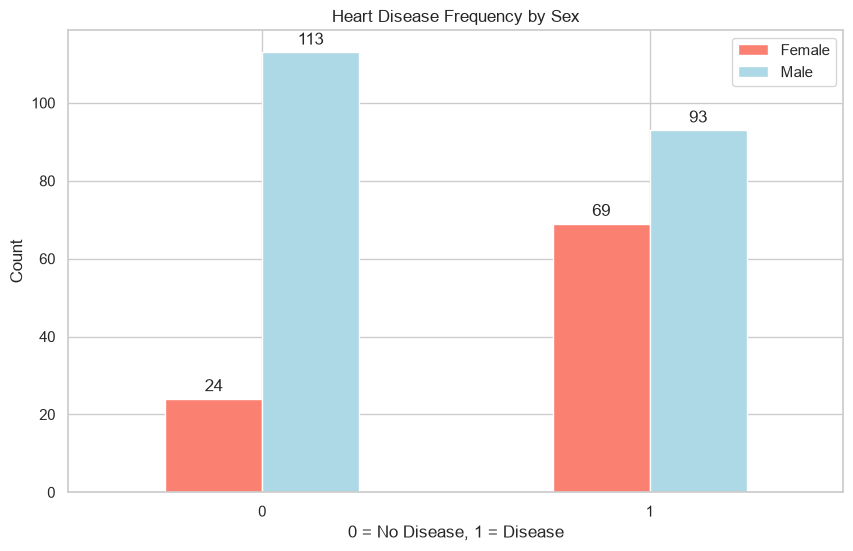

In [16]:
ax = pd.crosstab(df["target"], df["sex"]).plot(
    kind="bar",
    figsize=(10, 6),
    color=["salmon", "lightblue"],
)
plt.title("Heart Disease Frequency by Sex")
plt.xlabel("0 = No Disease, 1 = Disease")
plt.ylabel("Count")
plt.legend(["Female", "Male"])
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.show()

**Insight:** Raw counts are dominated by males because there are more males in the sample. Disease *rate* tells a different story: females show a higher share with disease (~74%) than males (~45%). Always compare rates within each sex, not only stacked counts.

## 6. Age vs max heart rate (`thalach`)

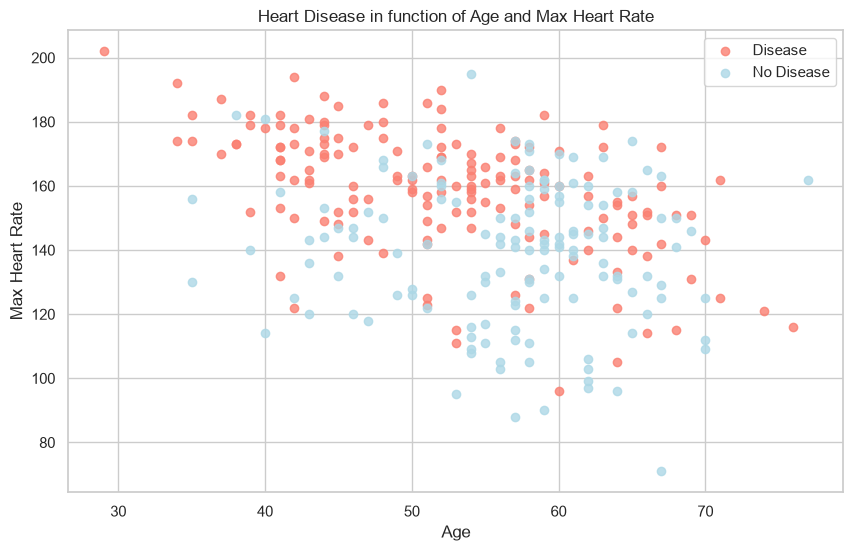

age            thalach       
             mean median        mean median
target                                     
0       56.525547   58.0  139.101449  142.0
1       52.444444   52.0  158.466667  161.0

In [17]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df.age[df.target == 1],
    df.thalach[df.target == 1],
    c="salmon",
    label="Disease",
    alpha=0.8,
)
plt.scatter(
    df.age[df.target == 0],
    df.thalach[df.target == 0],
    c="lightblue",
    label="No Disease",
    alpha=0.8,
)

plt.title("Heart Disease in function of Age and Max Heart Rate")
plt.xlabel("Age")
plt.ylabel("Max Heart Rate")
plt.legend()
plt.show()

df.groupby("target")[["age", "thalach"]].agg(["mean", "median"])

**Insight:** Disease cases (salmon) cluster toward slightly younger ages and higher max heart rate (mean `thalach` ~158 vs ~139). There is still plenty of overlap, so age and `thalach` help but will not separate classes alone.

## 7. Age and max heart rate by target (boxplots)

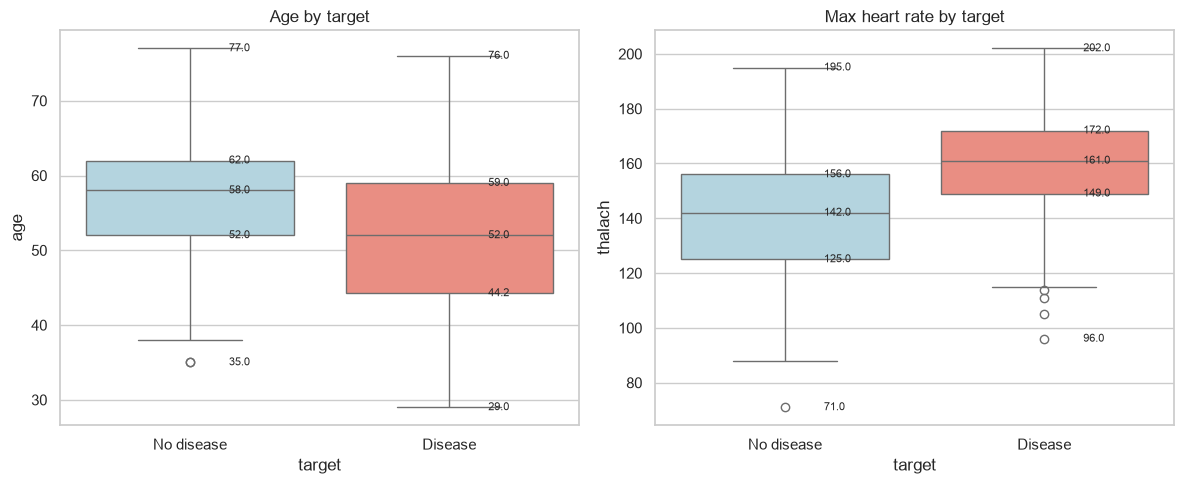

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

columns = ["age", "thalach"]
titles = ["Age by target", "Max heart rate by target"]

for ax, column, title in zip(axes, columns, titles):

    sns.boxplot(
        data=df,
        x="target",
        y=column,
        hue="target",
        ax=ax,
        palette=["lightblue", "salmon"],
        legend=False
    )

    ax.set_title(title)
    ax.set_xticks([0, 1], labels=["No disease", "Disease"])

    for target in [0, 1]:
        values = df.loc[df["target"] == target, column]

        stats = [
            values.min(),
            values.quantile(0.25),
            values.median(),
            values.quantile(0.75),
            values.max()
        ]

        for value in stats:
            ax.text(
                target + 0.15,
                value,
                f"{value:.1f}",
                fontsize=8,
                va="center"
            )

plt.tight_layout()
plt.show()


**Insight:** The boxplots confirm the scatter: disease patients have a lower median age and a clearly higher median `thalach`. Outliers exist on both sides — keep robust models / check leverage points during training.

## 8. Chest pain type (`cp`) vs target

In [21]:
pd.crosstab(df["cp"], df["target"])

target,0,1
cp,,
Asymptomatic,7,16
Atypical angina,9,41
Non-anginal pain,18,69
Typical angina,104,39


In [22]:
df.groupby("cp")["target"].agg(["count", "mean"])

,count,mean
cp,,
Asymptomatic,23,0.695652
Atypical angina,50,0.820000
Non-anginal pain,87,0.793103
Typical angina,143,0.272727


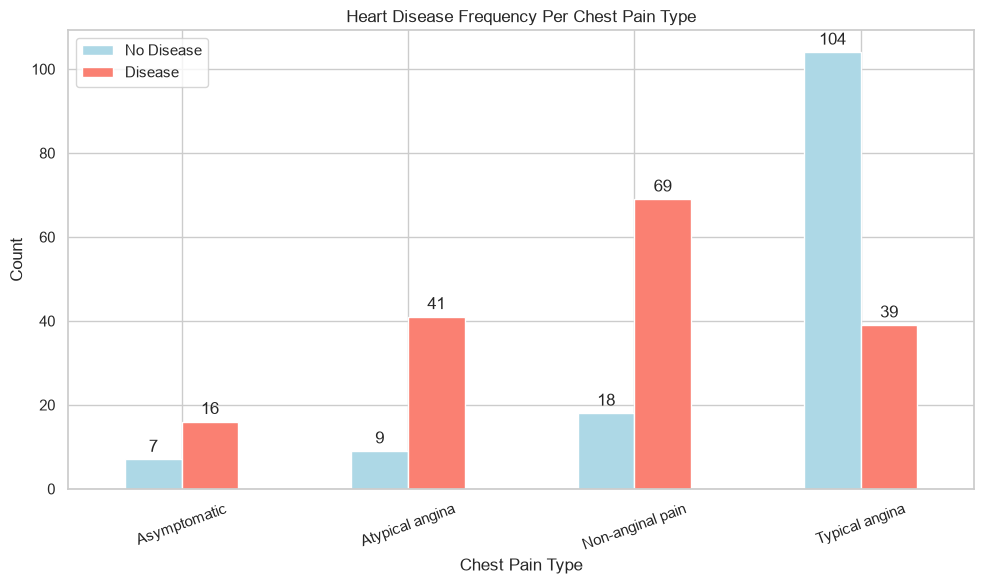

In [23]:
ax = pd.crosstab(df["cp"], df["target"]).plot(
    kind="bar",
    figsize=(10, 6),
    color=["lightblue", "salmon"],
)
plt.title("Heart Disease Frequency Per Chest Pain Type")
plt.xlabel("Chest Pain Type")
plt.ylabel("Count")
plt.legend(["No Disease", "Disease"])
plt.xticks(rotation=20)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()

**Insight:** Disease rate swings hard by chest pain type. Typical angina is common but has a low disease rate (~27%), while atypical angina, non-anginal pain, and asymptomatic groups sit much higher (~70–82%). `cp` is a strong categorical signal for the model.

## 9. ST depression (`oldpeak`) by target

In [24]:
df.groupby("target")["oldpeak"].agg(["mean", "median", "std"])

,mean,median,std
target,,,
0,1.585507,1.4,1.300340
1,0.583030,0.2,0.780683


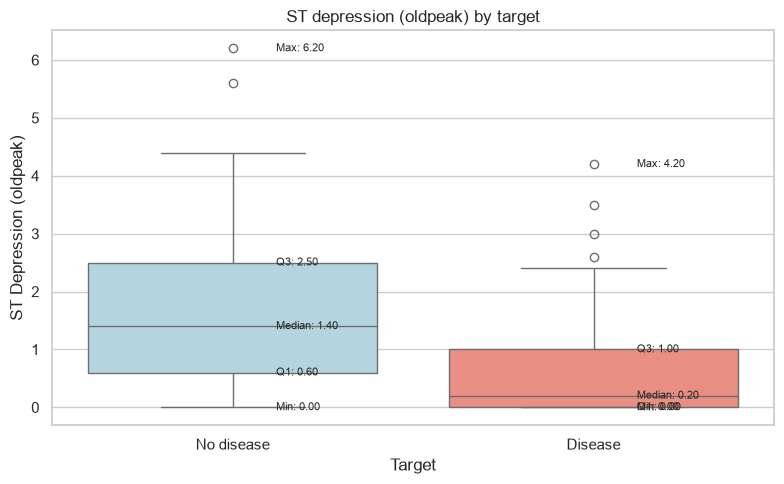

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="target",
    y="oldpeak",
    hue="target",
    palette=["lightblue", "salmon"],
    legend=False,
    ax=ax
)

for target in [0, 1]:
    values = df.loc[df["target"] == target, "oldpeak"]

    stats = {
        "Min": values.min(),
        "Q1": values.quantile(0.25),
        "Median": values.median(),
        "Q3": values.quantile(0.75),
        "Max": values.max()
    }

    for label, value in stats.items():
        ax.text(
            target + 0.12,
            value,
            f"{label}: {value:.2f}",
            fontsize=8,
            va="center"
        )

ax.set_title("ST depression (oldpeak) by target")
ax.set_xticks([0, 1], ["No disease", "Disease"])
ax.set_xlabel("Target")
ax.set_ylabel("ST Depression (oldpeak)")

plt.tight_layout()
plt.show()

**Insight:** In this dataset, no-disease rows show higher `oldpeak` (median ~1.4) than disease rows (median ~0.2). That makes `oldpeak` one of the strongest numeric separators — check its correlation with `target` in the heatmap next.

## 10. Major vessels (`ca`) vs target

In [29]:
pd.crosstab(df["ca"], df["target"])

target,0,1
ca,,
0,45,130
1,44,21
2,31,7
3,17,3
4,1,4


In [30]:
df.groupby("ca")["target"].agg(["count", "mean"])

,count,mean
ca,,
0,175,0.742857
1,65,0.323077
2,38,0.184211
3,20,0.150000
4,5,0.800000


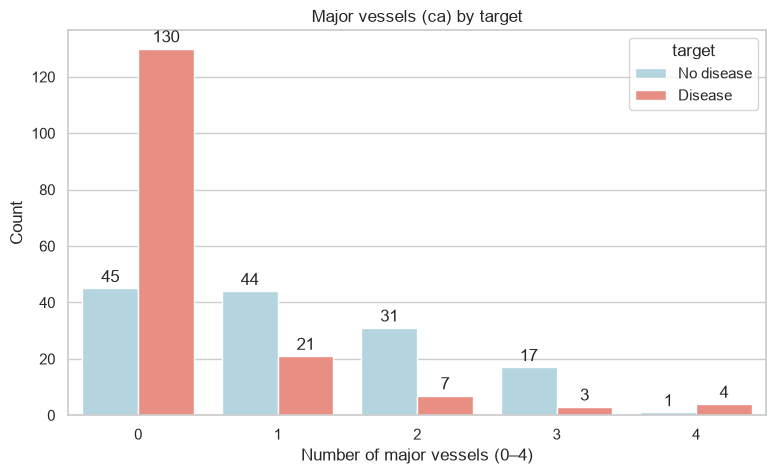

In [31]:
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x="ca", hue="target", palette=["lightblue", "salmon"])
plt.title("Major vessels (ca) by target")
plt.xlabel("Number of major vessels (0–4)")
plt.ylabel("Count")
plt.legend(title="target", labels=["No disease", "Disease"])
for container in ax.containers:
    ax.bar_label(container, padding=2)
plt.show()

**Insight:** Disease share falls as `ca` rises from 0 → 3 (~74% at 0 vessels vs ~15% at 3). The `ca=4` bin is tiny (n≈5) and noisy — treat it carefully or merge rare levels before modeling.

## 11. Exercise ST slope (`slope`) vs target

In [32]:
df.groupby("slope")["target"].agg(["count", "mean"])

,count,mean
slope,,
Downsloping,142,0.753521
Flatsloping,140,0.350000
Upsloping,21,0.428571


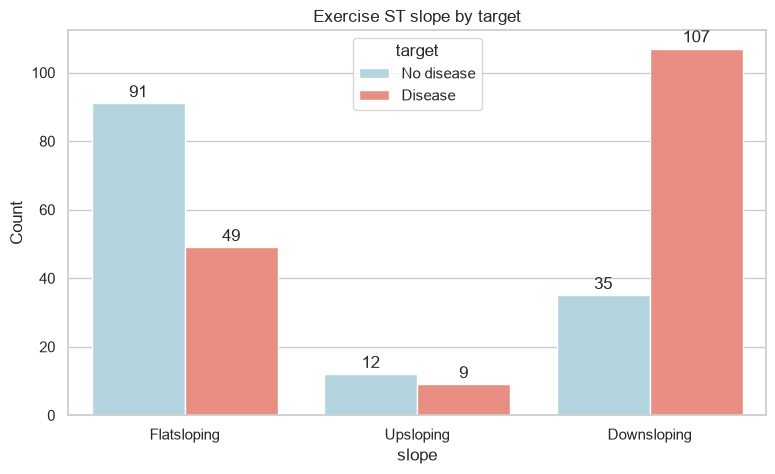

In [33]:
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x="slope", hue="target", palette=["lightblue", "salmon"])
plt.title("Exercise ST slope by target")
plt.ylabel("Count")
plt.legend(title="target", labels=["No disease", "Disease"])
for container in ax.containers:
    ax.bar_label(container, padding=2)
plt.show()

**Insight:** Downsloping ST segments show the highest disease rate (~75%), flat sloping the lowest (~35%), with upsloping in between on a smaller count. Slope is another useful categorical feature alongside `cp` and `exang`.

## 12. Age bins vs disease rate

In [34]:
df_age = df.dropna(subset=["age"]).copy()
df_age["age_bin"] = pd.cut(
    df_age["age"],
    bins=[0, 40, 50, 60, 70, 100],
    labels=["<=40", "41-50", "51-60", "61-70", "70+"],
)
age_rate = df_age.groupby("age_bin", observed=True)["target"].agg(["count", "mean"])
age_rate

,count,mean
age_bin,,
<=40,19,0.684211
41-50,75,0.693333
51-60,128,0.492188
61-70,72,0.416667
70+,5,0.800000


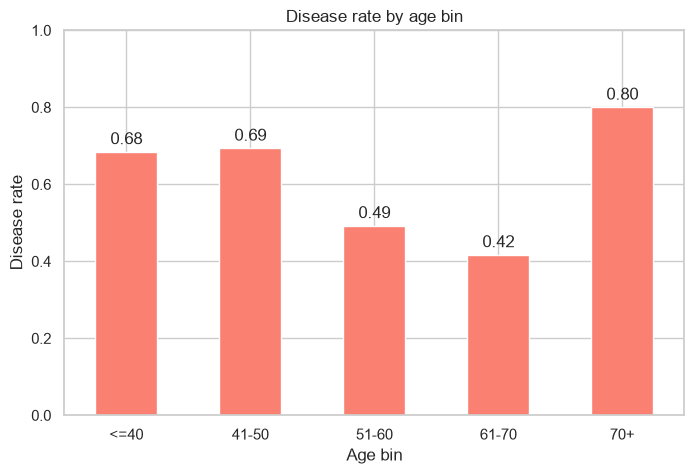

In [35]:
ax = age_rate["mean"].plot(kind="bar", color="salmon", figsize=(8, 5))
plt.title("Disease rate by age bin")
plt.xlabel("Age bin")
plt.ylabel("Disease rate")
plt.xticks(rotation=0)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.ylim(0, 1)
plt.show()

**Insight:** In this sample, disease rate is highest in the younger bins (~68–69% for ≤50) and drops through the 50s/60s (~49% then ~42%). The 70+ bin is tiny (n≈5), so do not over-read that spike — prefer continuous `age` plus stratification over tiny bins for modeling.

## 13. Cholesterol, BP, exercise angina, fasting sugar

In [36]:
print("Disease rate by exang:")
print(df.groupby("exang")["target"].mean())
print("\nDisease rate by fbs:")
print(df.groupby("fbs")["target"].mean())

Disease rate by exang:
exang
no     0.696078
yes    0.232323
Name: target, dtype: float64

Disease rate by fbs:
fbs
False    0.550388
True     0.511111
Name: target, dtype: float64


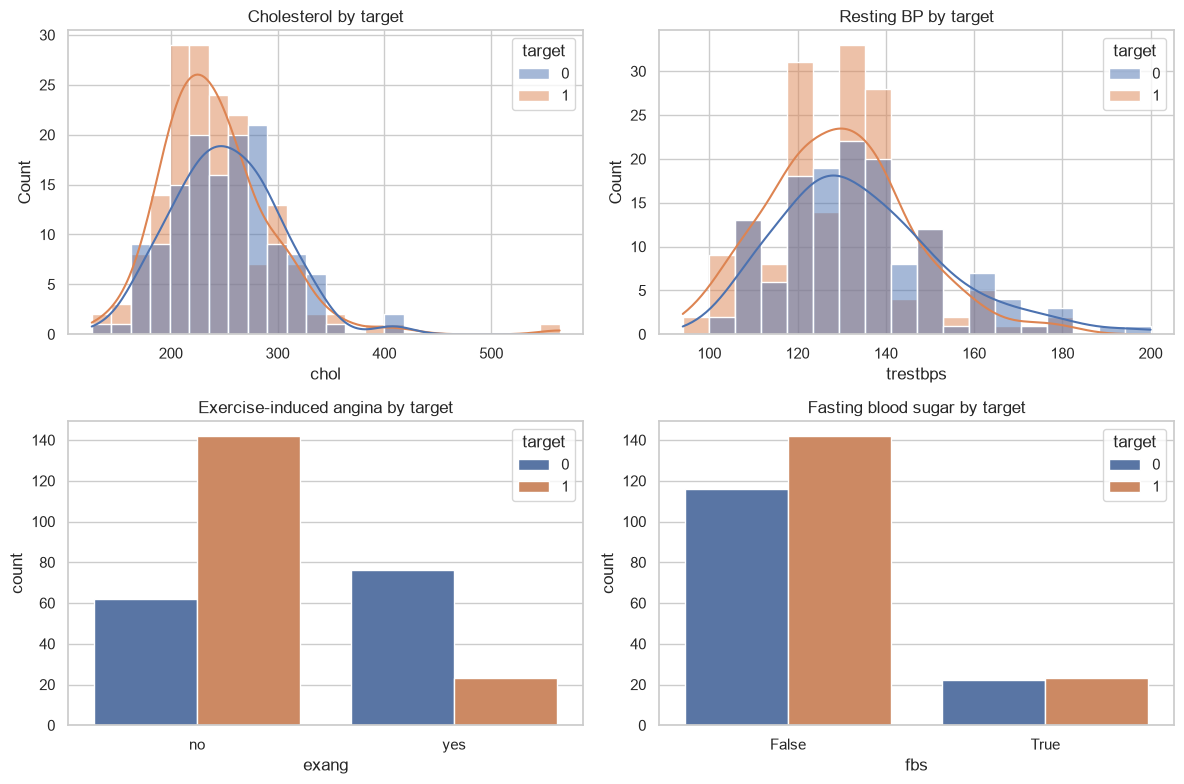

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=df, x="chol", hue="target", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Cholesterol by target")

sns.histplot(data=df, x="trestbps", hue="target", kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Resting BP by target")

sns.countplot(data=df, x="exang", hue="target", ax=axes[1, 0])
axes[1, 0].set_title("Exercise-induced angina by target")

sns.countplot(data=df, x="fbs", hue="target", ax=axes[1, 1])
axes[1, 1].set_title("Fasting blood sugar by target")

plt.tight_layout()
plt.show()

**Insight:** `exang` separates well — no exercise angina has a much higher disease rate (~70%) than yes (~23%). `chol` and `trestbps` overlap heavily between classes. `fbs` barely moves the rate (~55% vs ~51%), so it is a weak standalone signal.

## 14. Correlation matrix (numeric columns)

In [38]:
corr = df.select_dtypes(include="number").corr()
corr

,age,trestbps,chol,thalach,oldpeak,ca,thal,target
age,1.000000,0.289362,0.210711,-0.387722,0.215473,0.276204,0.071925,-0.225472
trestbps,0.289362,1.000000,0.123174,-0.046698,0.193216,0.101389,0.062210,-0.144931
chol,0.210711,0.123174,1.000000,-0.009940,0.053952,0.070511,0.098803,-0.085239
thalach,-0.387722,-0.046698,-0.009940,1.000000,-0.344187,-0.213177,-0.096439,0.421741
oldpeak,0.215473,0.193216,0.053952,-0.344187,1.000000,0.222682,0.210244,-0.430696
ca,0.276204,0.101389,0.070511,-0.213177,0.222682,1.000000,0.151832,-0.391724
thal,0.071925,0.062210,0.098803,-0.096439,0.210244,0.151832,1.000000,-0.344029
target,-0.225472,-0.144931,-0.085239,0.421741,-0.430696,-0.391724,-0.344029,1.000000


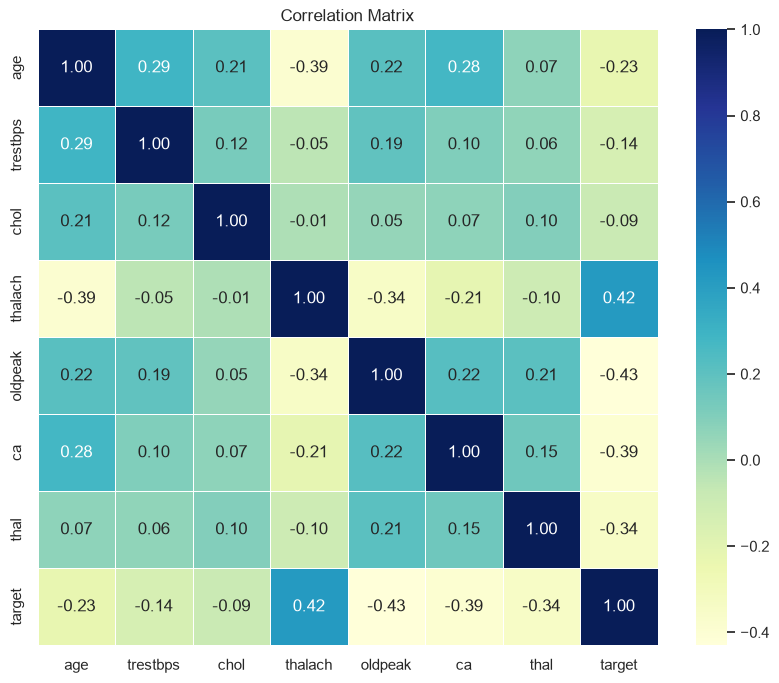

oldpeak    -0.430696
thalach     0.421741
ca         -0.391724
thal       -0.344029
age        -0.225472
trestbps   -0.144931
chol       -0.085239
Name: target, dtype: float64

In [39]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

corr["target"].drop("target").sort_values(key=abs, ascending=False)

**Insight:** Strongest numeric links to `target` are `oldpeak` (~-0.43), `thalach` (~0.42), `ca` (~-0.39), then `thal` and `age`. `chol` and `trestbps` are weak. Categorical drivers (`cp`, `exang`, `slope`, `sex`) are outside this matrix — combine both views when choosing features.

## Quick takeaways

- **Balance:** Target is nearly even (~54% disease) : accuracy is usable, but still track recall/ROC.
- **Gender:** Sample is male-heavy, yet disease *rate* is higher in females, use rates and stratified evaluation.
- **Strong categoricals:** `cp`, `exang`, `slope`, and `ca` show clear disease-rate gaps.
- **Strong numerics:** `oldpeak` and `thalach` (with `age`) separate better than `chol` / `trestbps` / `fbs`.
- **Data quality:** A few missing `age`/`sex` values and rare bins (`ca=4`, age 70+) need care before modeling.
- **Modeling cue:** Encode categoricals, keep `oldpeak`/`thalach`/`ca`/`cp`/`exang`, and prefer stratified splits.